In [1]:
print("test")

test


In [2]:
# Import necessary libraries for building and training the model
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Initialize PyTorch and check for CUDA availability
print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1+cu130
Device : cpu


In [4]:
# Load the MNIST dataset and create data loaders for training and testing
# Define a transformation to convert the images to tensors
transform = transforms.ToTensor()

# Load the MNIST dataset for training and testing
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)
# The MNIST dataset is a collection of handwritten digits commonly used for training various image processing systems. It consists of 60,000 training images and 10,000 testing images, each of size 28x28 pixels. The dataset is widely used in machine learning and computer vision research for tasks such as image classification and generative modeling.
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders for training and testing
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)
# Print the number of samples in the training and testing datasets
print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


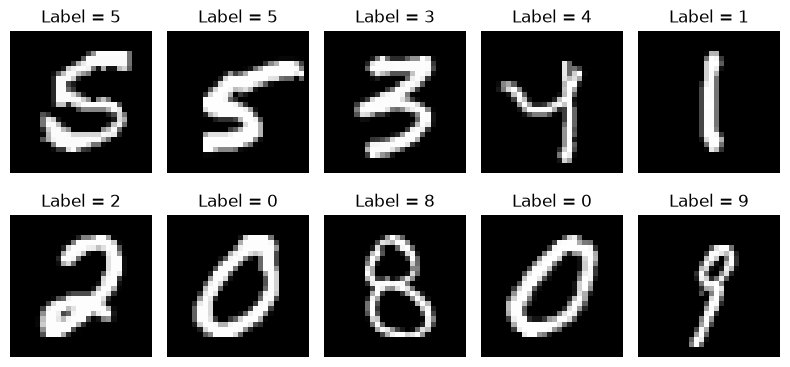

In [5]:
# Visualize some samples from the training dataset

images, labels = next(iter(train_loader))
# Display the first 10 images and their corresponding labels
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Define a simple feedforward neural network for classifying MNIST digits
class Classifier(nn.Module):
    # Initialize the network layers
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    # Define the forward pass of the network
    def forward(self, x):
        return self.net(x)
# Instantiate the classifier and move it to the appropriate device (CPU or GPU)
classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [7]:
# Define the loss function and optimizer for training the classifier
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [8]:
# Define a function to train the classifier for a specified number of epochs
# C
def train_classifier(model, loader, epochs=3):
    model.train()
    # Condition pour vérifier si le modèle est en mode entraînement
    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )
# Train the classifier for 3 epochs using the training data loader
train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4108
Epoch 2/3 - Loss = 0.1940
Epoch 3/3 - Loss = 0.1416


In [9]:
# Define a function to evaluate the classifier's accuracy on the test dataset
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0
    # Condition pour vérifier si le modèle est en mode évaluation
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device) # Move the input data and labels to the appropriate device (CPU or GPU)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item() # Increment the count of correct predictions
            total += y.size(0)
    # Return the accuracy as the ratio of correct predictions to total samples
    return correct / total
# Evaluate the classifier on the test dataset and print the accuracy
accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.22%


### Une autre façon de verifier le model

In [10]:
# Evaluate the classifier's accuracy on the test dataset
from torcheval.metrics import MulticlassAccuracy
# Define a function to evaluate the classifier's accuracy on the test dataset
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()

# Evaluate the classifier on the test dataset and print the accuracy
accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

/home/superrama/model_generatifs/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy = 96.22%


# Partie II - Autoencodeur

## 2-1 Idée générale

In [11]:
# Define a simple autoencoder model for dimensionality reduction and reconstruction of MNIST images
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        
        # Define the encoder and decoder networks for the autoencoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        # Define the decoder network for reconstructing images from the latent space
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    # Define the encoding function that maps input images to the latent space
    def encode(self, x):
        return self.encoder(x)
    # Define the decoding function that reconstructs images from the latent space
    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)
    # Define the forward pass of the autoencoder, which encodes the input and then decodes it back to the original space
    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

# Instantiate the autoencoder with a latent dimension of 2 and move it to the appropriate device (CPU or GPU)
ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

## 2-2 Loss de reconstruction

In [12]:
# Define the loss function and optimizer for training the autoencoder
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
# Define a function to train the autoencoder for a specified number of epochs
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        # Loop through the training data loader and perform forward and backward passes to update the model parameters
        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )
# Train the autoencoder for 5 epochs using the training data loader
train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0658
Epoch 2/5 - Loss = 0.0526
Epoch 3/5 - Loss = 0.0508
Epoch 4/5 - Loss = 0.0491
Epoch 5/5 - Loss = 0.0473


## 2-3 Visualisation des reconstruction

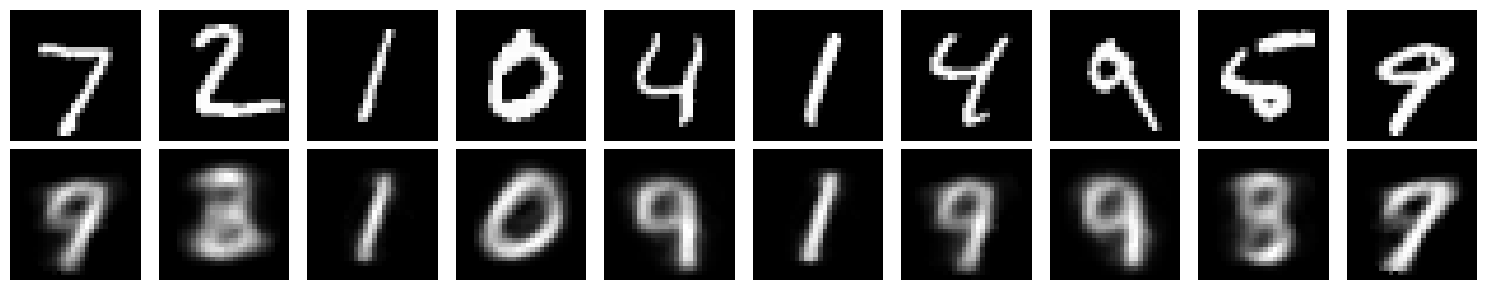

In [13]:
# Evaluate the autoencoder's reconstruction performance on the test dataset
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)
# Use the trained autoencoder to reconstruct the input images without computing gradients
with torch.no_grad():
    x_hat = ae(x)

# Visualize the original and reconstructed images side by side for comparison
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
# Loop through the first 10 images and display the original and reconstructed images in a grid
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
# Set the y-axis labels for the original and reconstructed images
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")
# Adjust the layout of the plots to prevent overlap and display the figure
plt.tight_layout()
plt.show()

## 2-4 Visualisation de l'espace latent

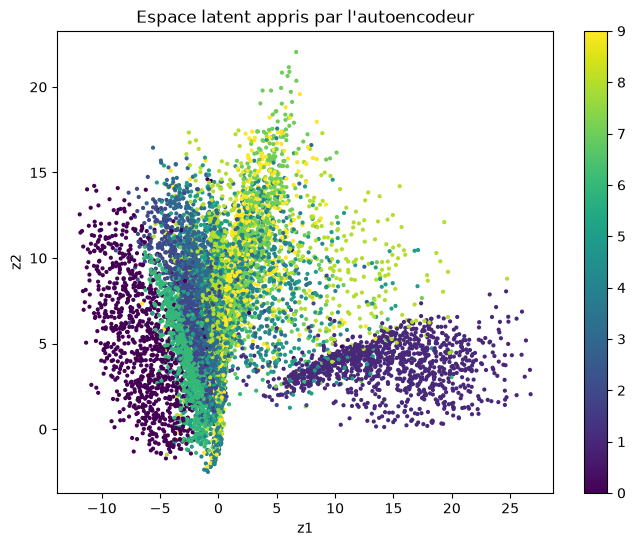

In [14]:

## Visualisation de l'espace latent
ae.eval()

zs = []
ys = []
# Use the trained autoencoder to encode the test images into the latent space without computing gradients
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)
# Concatenate the latent representations and labels into NumPy arrays for visualization
Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()
# Create a scatter plot of the latent space representations, coloring the points by their corresponding labels
plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

# Generate à partir d'un chiffre  inconnue

In [15]:
import torch
import matplotlib.pyplot as plt
# Define a function to generate an average image of a specified digit using the trained autoencoder
@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")
    # Get the device of the model's parameters to ensure that the input data is moved to the same device for computation
    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0
    # Loop through the data loader to accumulate the latent representations of the specified digit
    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]
    # Check if any images of the specified digit were found; if not, raise an error
    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    # Compute the average latent representation and decode it to generate the average image of the specified digit
    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu() 

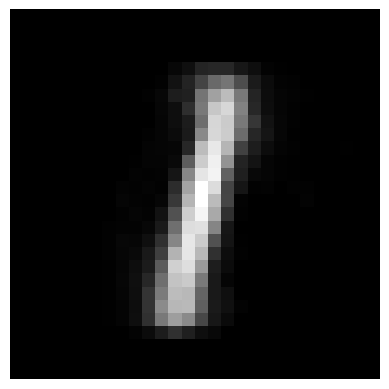

In [16]:
# model : ton autoencodeur entraîné
# train_loader : ton DataLoader MNIST
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
plt.show()

# Partie III Loss en Entrainement du VAE

In [20]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [19]:
# Define the loss function for the Variational Autoencoder (VAE), which combines reconstruction loss and KL divergence
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    # Compute the KL divergence loss, which measures how much the learned latent distribution deviates from a standard normal distribution
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )
    # Combine the reconstruction loss and KL divergence loss
    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [21]:
## Entrainement
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
# Define a function to train the Variational Autoencoder (VAE) for a specified number of epochs
def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()
    # Train the VAE for the specified number of epochs
    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )
# Train the Variational Autoencoder (VAE) for 20 epochs using the training data loader
train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=192.96 | Rec=188.67 | KL=4.29
Epoch 2/20 | Loss=166.74 | Rec=161.90 | KL=4.83
Epoch 3/20 | Loss=161.22 | Rec=156.02 | KL=5.20
Epoch 4/20 | Loss=157.59 | Rec=152.11 | KL=5.47
Epoch 5/20 | Loss=155.12 | Rec=149.49 | KL=5.63
Epoch 6/20 | Loss=153.14 | Rec=147.37 | KL=5.77
Epoch 7/20 | Loss=151.53 | Rec=145.68 | KL=5.85
Epoch 8/20 | Loss=150.20 | Rec=144.27 | KL=5.93
Epoch 9/20 | Loss=148.95 | Rec=142.92 | KL=6.03
Epoch 10/20 | Loss=147.92 | Rec=141.85 | KL=6.08
Epoch 11/20 | Loss=147.22 | Rec=141.09 | KL=6.13
Epoch 12/20 | Loss=146.33 | Rec=140.12 | KL=6.20
Epoch 13/20 | Loss=145.72 | Rec=139.48 | KL=6.24
Epoch 14/20 | Loss=145.04 | Rec=138.76 | KL=6.28
Epoch 15/20 | Loss=144.56 | Rec=138.23 | KL=6.33
Epoch 16/20 | Loss=144.15 | Rec=137.78 | KL=6.37
Epoch 17/20 | Loss=143.66 | Rec=137.28 | KL=6.38
Epoch 18/20 | Loss=143.32 | Rec=136.91 | KL=6.41
Epoch 19/20 | Loss=142.86 | Rec=136.42 | KL=6.44
Epoch 20/20 | Loss=142.66 | Rec=136.19 | KL=6.47
